# Telugu results: TF-IDF baseline vs XLM-RoBERTa (no context)

This notebook **trains nothing**. It reads the outputs that `context_aware_sentiment_analysis.ipynb` saved to `outputs/` after the baseline and Model B were trained and evaluated on the untouched TeSent test split.

**Data actually used:** Telugu (TeSent) only. English was excluded because its numeric labels are undocumented. Code-mixed was excluded because its labels are hate/non-hate, not sentiment. See `outputs/audit_report.json`.

> **Model C (context-aware XLM-RoBERTa): Skipped — no real conversation_id/message_order available.** None of the supplied datasets has a real `conversation_id` or `message_order`, so `context_text == cleaned_text` for every row. Model C would have had the same input and hyperparameters as Model B: a duplicate experiment that would cost several more hours of CPU time for no new information. Context-aware training is deferred to the Colab GPU run (`colab_final_multilingual_sentiment.ipynb`), which uses manually annotated conversations.

In [1]:
import json, os, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
from sklearn.metrics import classification_report, confusion_matrix

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 220)
OUT = Path(os.environ.get("REPORT_OUT", r"D:\NLP\outputs"))
CLASS_NAMES = ["Negative", "Neutral", "Positive"]
ID2LABEL = dict(enumerate(CLASS_NAMES))

mb = json.load(open(OUT / "metrics_baseline.json", encoding="utf-8"))
mnc = json.load(open(OUT / "metrics_no_context.json", encoding="utf-8"))
test = pd.read_csv(OUT / "test.csv")
print("Test split:", len(test), "rows |", test["language_type"].value_counts().to_dict(), "|",
      test["label"].map(ID2LABEL).value_counts().to_dict())

Test split: 3168 rows | {'telugu': 3168} | {'Neutral': 1439, 'Negative': 879, 'Positive': 850}


## 1. Telugu comparison: baseline vs Model B

In [2]:
SKIP_NOTE = ("Intentionally skipped: no real conversation_id/message_order, so context_text == cleaned_text; "
             "Model C would duplicate Model B.")

def row(m):
    t = m["per_language"]["telugu"]
    return {"Model name": m["model"], "Input used": m["input"], "Test accuracy": round(m["accuracy"], 4),
            "Test macro F1": round(m["macro_f1"], 4), "Test weighted F1": round(m["weighted_f1"], 4),
            "Telugu macro F1": round(t["macro_f1"], 4), "English macro F1": "N/A (excluded)",
            "Code-mixed macro F1": "N/A (excluded)",
            "Best validation macro F1": round(m["best_validation_macro_f1"], 4),
            "Mean test confidence": round(m["confidence"]["mean"], 4)}

comparison = pd.DataFrame([
    {**row(mb), "Notes": "TF-IDF word 1-2 grams (20k) + LogisticRegression(class_weight=balanced). Telugu only."},
    {**row(mnc), "Notes": "xlm-roberta-base fine-tuned on current message only; best epoch by val macro F1. Telugu only."},
    {"Model name": "XLM-RoBERTa (context-aware)", "Input used": "context_text",
     **{k: "Skipped — no real conversation_id/message_order available." for k in ["Test accuracy", "Test macro F1", "Test weighted F1", "Telugu macro F1",
                               "English macro F1", "Code-mixed macro F1", "Best validation macro F1", "Mean test confidence"]},
     "Notes": SKIP_NOTE},
])
display(comparison)

per_class = pd.DataFrame({
    (name, metric): {c: m["per_class"][c][metric] for c in CLASS_NAMES}
    for name, m in [("Baseline", mb), ("XLM-R no context", mnc)] for metric in ["precision", "recall", "f1"]
}).round(4)
per_class["support"] = [mnc["per_class"][c]["support"] for c in CLASS_NAMES]
print("Per-class comparison on the test split:")
display(per_class)

comparison.drop(columns=["Mean test confidence"]).to_csv(OUT / "model_comparison.csv", index=False, encoding="utf-8-sig")
lang_rows = []
for m in (mb, mnc):
    for lang, v in m["per_language"].items():
        lang_rows.append({"model": m["model"], "language_type": lang, "n_test": v["n"], "status": v["status"],
                          "accuracy": v["accuracy"], "macro_f1": v["macro_f1"], "weighted_f1": v["weighted_f1"]})
lang_rows.append({"model": "XLM-RoBERTa (context-aware)", "language_type": "all", "n_test": 0, "status": SKIP_NOTE,
                  "accuracy": None, "macro_f1": None, "weighted_f1": None})
pd.DataFrame(lang_rows).to_csv(OUT / "per_language_results.csv", index=False, encoding="utf-8-sig")
with open(OUT / "metrics_context_aware.json", "w", encoding="utf-8") as f:
    json.dump({"model": "XLM-RoBERTa (context-aware)", "status": "Skipped — no real conversation_id/message_order available.", "reason": SKIP_NOTE}, f, indent=2, ensure_ascii=False)
print("Saved model_comparison.csv, per_language_results.csv, metrics_context_aware.json (skip record)")

,Model name,Input used,Test accuracy,Test macro F1,Test weighted F1,Telugu macro F1,English macro F1,Code-mixed macro F1,Best validation macro F1,Mean test confidence,Notes
0,TF-IDF + Logistic Regression,cleaned_text,0.6285,0.6232,0.6287,0.6232,N/A (excluded),N/A (excluded),0.6077,0.5701,TF-IDF word 1-2 grams (20k) + LogisticRegression(class_weight=balanced). Telugu only.
1,XLM-RoBERTa (no context),cleaned_text,0.6979,0.6985,0.6979,0.6985,N/A (excluded),N/A (excluded),0.7126,0.8779,xlm-roberta-base fine-tuned on current message only; best epoch by val macro F1. Telugu only.
2,XLM-RoBERTa (context-aware),context_text,Skipped — no real conversation_id/message_order available.,Skipped — no real conversation_id/message_order available.,Skipped — no real conversation_id/message_order available.,Skipped — no real conversation_id/message_order available.,Skipped — no real conversation_id/message_order available.,Skipped — no real conversation_id/message_order available.,Skipped — no real conversation_id/message_order available.,Skipped — no real conversation_id/message_order available.,"Intentionally skipped: no real conversation_id/message_order, so context_text == cleaned_text; Model C would duplicate Model B."


Per-class comparison on the test split:


Baseline                 XLM-R no context                 support
         precision  recall      f1        precision  recall      f1        
Negative    0.5898  0.6428  0.6151           0.6980  0.7019  0.6999     879
Neutral     0.6643  0.6421  0.6530           0.7096  0.6810  0.6950    1439
Positive    0.6129  0.5906  0.6016           0.6800  0.7224  0.7005     850

Saved model_comparison.csv, per_language_results.csv, metrics_context_aware.json (skip record)


## 2. Model B: XLM-RoBERTa without context (real test results)

In [3]:
pred = pd.read_csv(OUT / "predictions_no_context.csv")
y, p = pred["actual_id"].values, pred["pred_id"].values
print(f"Accuracy    : {mnc['accuracy']:.4f}")
print(f"Macro F1    : {mnc['macro_f1']:.4f}")
print(f"Weighted F1 : {mnc['weighted_f1']:.4f}")
print(f"Best validation macro F1: {mnc['best_validation_macro_f1']:.4f}")
print(f"Confidence  : mean {mnc['confidence']['mean']:.4f} | when correct {mnc['confidence']['mean_when_correct']:.4f} "
      f"| when wrong {mnc['confidence']['mean_when_wrong']:.4f}")
print("\nClassification report (test):")
print(classification_report(y, p, labels=[0, 1, 2], target_names=CLASS_NAMES, digits=4, zero_division=0))

hist_path = OUT / "xlm_roberta_no_context" / "validation_history.csv"
if hist_path.exists():
    print("Validation history (per epoch):")
    display(pd.read_csv(hist_path)[["epoch", "eval_loss", "eval_accuracy", "eval_macro_f1", "eval_weighted_f1"]].round(4))

Accuracy    : 0.6979
Macro F1    : 0.6985
Weighted F1 : 0.6979
Best validation macro F1: 0.7126
Confidence  : mean 0.8779 | when correct 0.9059 | when wrong 0.8133

Classification report (test):
              precision    recall  f1-score   support

    Negative     0.6980    0.7019    0.6999       879
     Neutral     0.7096    0.6810    0.6950      1439
    Positive     0.6800    0.7224    0.7005       850

    accuracy                         0.6979      3168
   macro avg     0.6959    0.7018    0.6985      3168
weighted avg     0.6984    0.6979    0.6979      3168

Validation history (per epoch):


,epoch,eval_loss,eval_accuracy,eval_macro_f1,eval_weighted_f1
0,1.0,0.7417,0.6866,0.6853,0.6866
1,2.0,0.7806,0.6831,0.6826,0.6822
2,3.0,0.7348,0.7124,0.7073,0.7110
3,4.0,0.7150,0.7096,0.7111,0.7095
4,5.0,0.8229,0.7115,0.7126,0.7113


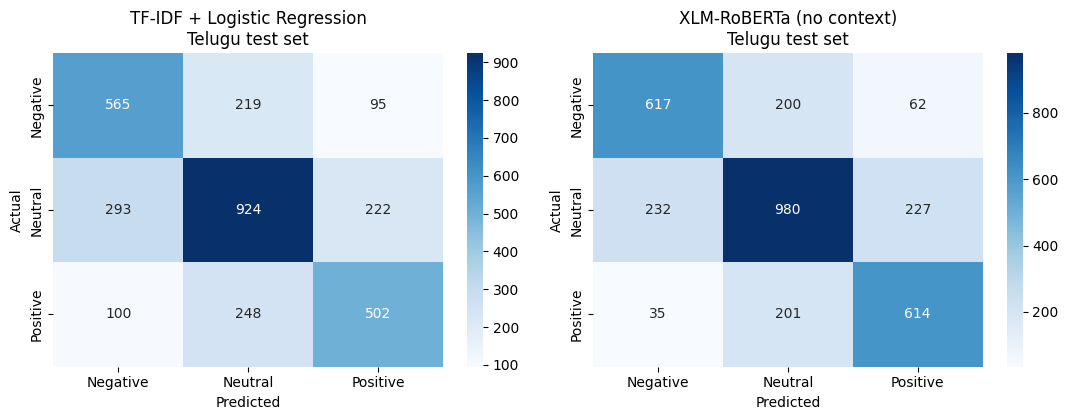

Rows = actual, columns = predicted
Baseline:


,pred_Negative,pred_Neutral,pred_Positive
true_Negative,565,219,95
true_Neutral,293,924,222
true_Positive,100,248,502


XLM-RoBERTa (no context):


,pred_Negative,pred_Neutral,pred_Positive
true_Negative,617,200,62
true_Neutral,232,980,227
true_Positive,35,201,614


In [4]:
cm = pd.read_csv(OUT / "confusion_matrix_no_context.csv", index_col=0)
assert (cm.values == confusion_matrix(y, p, labels=[0, 1, 2])).all()
cm_b = pd.read_csv(OUT / "confusion_matrix_baseline.csv", index_col=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, (title, mat) in zip(axes, [("TF-IDF + Logistic Regression", cm_b), ("XLM-RoBERTa (no context)", cm)]):
    sns.heatmap(mat.values, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f"{title}\nTelugu test set"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
fig.tight_layout(); fig.savefig(OUT / "confusion_matrices_telugu_side_by_side.png", dpi=150)
plt.show(); plt.close(fig)
print("Rows = actual, columns = predicted")
print("Baseline:"); display(cm_b)
print("XLM-RoBERTa (no context):"); display(cm)

## 3. Model B: 30 misclassified examples

The 15 most confident and the 15 least confident mistakes on the test split. **`likely_error_reason` is a rule-based heuristic** (negation words, emojis, mixed script, low confidence, annotator disagreement from TeSent's three annotations, Neutral-vs-polar overlap). It is not a verified cause.

In [5]:
NEGATIONS = ["not", "no", "never", "ledu", "kaadu", "avvale", "vaddu"]
EMOJI_RE = re.compile("[\U0001F300-\U0001FAFF\u2600-\u27BF\U0001F1E6-\U0001F1FF]")
TELUGU_RE = re.compile("[\u0C00-\u0C7F]")
LATIN_RE = re.compile("[A-Za-z]")
NEG_RE = re.compile(r"\b(" + "|".join(NEGATIONS) + r")\b|లేదు|కాదు|వద్దు|కాలేదు|లేను", re.IGNORECASE)

def heuristic_error_reason(r):
    reasons, text = [], str(r["cleaned_text"])
    if r["confidence"] < 0.5: reasons.append("low confidence prediction")
    if NEG_RE.search(text): reasons.append("negation handling")
    if EMOJI_RE.search(text): reasons.append("emoji ambiguity")
    if r["language_type"] == "code_mixed" or (TELUGU_RE.search(text) and LATIN_RE.search(text)):
        reasons.append("mixed-language ambiguity")
    if len(text.split()) <= 3: reasons.append("insufficient conversational context")
    ann = r.get("annotations")
    if isinstance(ann, str) and len({a.split("-")[0].strip() for a in ann.split("|")}) > 1:
        reasons.append("annotation ambiguity")
    if {r["actual_id"], r["pred_id"]} == {0, 2} and not reasons: reasons.append("sarcasm/implicit sentiment")
    return "; ".join(reasons) if reasons else "class overlap"

wrong = pred[pred["actual_id"] != pred["pred_id"]].copy()
wrong["likely_error_reason"] = wrong.apply(heuristic_error_reason, axis=1)
wrong["reason_type"] = "HEURISTIC (rule-based guess, not ground truth)"
wrong = wrong.sort_values("confidence", ascending=False)
k = min(30, len(wrong))
errors30 = pd.concat([wrong.head((k + 1) // 2), wrong.tail(k // 2)]).drop_duplicates()
cols = ["actual_label", "predicted_label", "confidence", "raw_text", "cleaned_text", "language_type",
        "annotations", "likely_error_reason", "reason_type"]
errors30 = errors30[cols].reset_index(drop=True)
errors30["confidence"] = errors30["confidence"].round(4)
errors30.to_csv(OUT / "misclassified_no_context_30.csv", index=False, encoding="utf-8-sig")
print(f"Total test mistakes: {len(wrong)} of {len(pred)}. Showing {len(errors30)} (saved misclassified_no_context_30.csv).")
print("\nError direction counts (all mistakes):")
display(pd.crosstab(wrong["actual_label"], wrong["predicted_label"]))
print("Heuristic reason tags across ALL mistakes (a mistake can have several):")
display(wrong["likely_error_reason"].str.split("; ").explode().value_counts().to_frame("count"))
display(errors30.drop(columns=["reason_type"]))

Total test mistakes: 957 of 3168. Showing 30 (saved misclassified_no_context_30.csv).

Error direction counts (all mistakes):


predicted_label,Negative,Neutral,Positive
actual_label,,,
Negative,0,200,62
Neutral,232,0,227
Positive,35,201,0


Heuristic reason tags across ALL mistakes (a mistake can have several):


,count
likely_error_reason,
annotation ambiguity,675
class overlap,181
negation handling,104
emoji ambiguity,87
mixed-language ambiguity,53
insufficient conversational context,35
low confidence prediction,33
sarcasm/implicit sentiment,25


,actual_label,predicted_label,confidence,raw_text,cleaned_text,language_type,annotations,likely_error_reason
0,Neutral,Positive,0.9943,నా కామెంట్ కు మీరు బదులిస్తే నా కృతజ్ఞతలు స్వీకరించారని భావిస్తాను . సంతోషిస్తాను సార్ . ప్లీజ్,నా కామెంట్ కు మీరు బదులిస్తే నా కృతజ్ఞతలు స్వీకరించారని భావిస్తాను . సంతోషిస్తాను సార్ . ప్లీజ్,telugu,Neutral|Positive|Neutral,annotation ambiguity
1,Neutral,Positive,0.9941,గుడ్ మూవీ . బట్ హీరో వైఫ్ . ?,గుడ్ మూవీ . బట్ హీరో వైఫ్ . ?,telugu,Neutral|Positive|Neutral,annotation ambiguity
2,Neutral,Positive,0.9926,"నాకు తెలిసినంతవరకూ జనాలు కధ బాగా ఉంది , ఫైట్స్ బాగా ఉన్నాయి అంటారు .","నాకు తెలిసినంతవరకూ జనాలు కధ బాగా ఉంది , ఫైట్స్ బాగా ఉన్నాయి అంటారు .",telugu,Positive|Neutral|Neutral,annotation ambiguity
3,Neutral,Positive,0.9925,"అన్న మీరు మన తెలుగు వల్లని కలిసినందుకు చాల సంతోషం నేను కూడా శ్రీలంక కి వెళతాను దయచేసి తెలుగు వాళ్ళని ఫోన్ నంబర్ తీసుకోండి , దయచేసి . మే...","అన్న మీరు మన తెలుగు వల్లని కలిసినందుకు చాల సంతోషం నేను కూడా శ్రీలంక కి వెళతాను దయచేసి తెలుగు వాళ్ళని ఫోన్ నంబర్ తీసుకోండి , దయచేసి . మేమ...",telugu,Neutral|Positive|Neutral,annotation ambiguity
4,Neutral,Positive,0.9917,బాగా డబ్బులు వచ్చాయి,బాగా డబ్బులు వచ్చాయి,telugu,Positive|Neutral|Neutral,insufficient conversational context; annotation ambiguity
5,Neutral,Positive,0.9913,"శిల్పుల నైపుణ్యాన్ని గుర్తిచినమీకుధన్యవాదములు , రామప్పస్థపతి , నాట్యశాస్త్ర , లయశాష్త్రమ్ కూడాతెలిసిన సర్వఙ్ఞుడుమహాశిల్పినిగురించితెల...","శిల్పుల నైపుణ్యాన్ని గుర్తిచినమీకుధన్యవాదములు , రామప్పస్థపతి , నాట్యశాస్త్ర , లయశాష్త్రమ్ కూడాతెలిసిన సర్వఙ్ఞుడుమహాశిల్పినిగురించితెలిపి...",telugu,Positive|Neutral|Neutral,annotation ambiguity
6,Neutral,Negative,0.9909,ఆ గ్రామాల్లో సుమారు < NUMBER > మందికి < NUMBER > . < NUMBER > . < NUMBER > న అన్నదాన కార్యక్రమం చేశాము . నిజంగా చాలా ద...,ఆ గ్రామాల్లో సుమారు < NUMBER > మందికి < NUMBER > . < NUMBER > . < NUMBER > న అన్నదాన కార్యక్రమం చేశాము . నిజంగా చాలా దారుణమైన సంఘటన,telugu,Neutral|Neutral|Negative,mixed-language ambiguity; annotation ambiguity
7,Neutral,Positive,0.9909,అది అన్నయ్య మజాకా మంచి మనుసున్న అది,అది అన్నయ్య మజాకా మంచి మనుసున్న అది,telugu,Neutral|Neutral|Positive,annotation ambiguity
8,Neutral,Negative,0.9908,రైతు కి కోపం వచ్చింది . !,రైతు కి కోపం వచ్చింది . !,telugu,Negative|Neutral|Neutral,annotation ambiguity
9,Neutral,Positive,0.9906,మీ గురించి ఎన్ని చెప్పినా తక్కువే అన్న గారు . దేవుడు మీ లాంటి మంచి వాళ్ళని చాలా మందిని ఈ భూమి మీద చాలా సంవ్సరాలుగా ఉంచాలని దేవుడిని కోర...,మీ గురించి ఎన్ని చెప్పినా తక్కువే అన్న గారు . దేవుడు మీ లాంటి మంచి వాళ్ళని చాలా మందిని ఈ భూమి మీద చాలా సంవ్సరాలుగా ఉంచాలని దేవుడిని కోరు...,telugu,Positive|Neutral|Neutral,annotation ambiguity


## 4. Status
- ✅ Baseline and Model B were trained and evaluated on Telugu; all their outputs are in `outputs/`.
- ⏭️ **Model C was intentionally skipped** because conversational metadata is missing (see the note at the top).
- ⛔ No further CPU training. The final multilingual and context-aware run is prepared in `colab_final_multilingual_sentiment.ipynb` for a Colab GPU. Its readiness gate refuses to train until TweetEval (English), CMTET (code-mixed, with documentation) and the manually annotated conversations are in place.